<a href="https://colab.research.google.com/github/yagna0505/NLP-project/blob/main/FAKE_NEWS_DETECTION_USING_NLP_AND_LINGUISTIC_FEATURE_ANALYSIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Load and inspect the dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from scipy.sparse import hstack, csr_matrix

fake_df = pd.read_csv("/content/Fake.csv")
real_df = pd.read_csv("/content/True.csv")

fake_df["label"] = 1
real_df["label"] = 0

df = pd.concat([fake_df, real_df], ignore_index=True)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate title-text pairs:",
      df.duplicated(subset=["title", "text"]).sum())

print("\nFirst five records:")
display(df.head())

Dataset shape: (44898, 5)

Columns: ['title', 'text', 'subject', 'date', 'label']

Class distribution:
label
1    23481
0    21417
Name: count, dtype: int64

Missing values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicate title-text pairs: 5793

First five records:


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",1
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",1


## **Perform exploratory data analysis (EDA)**

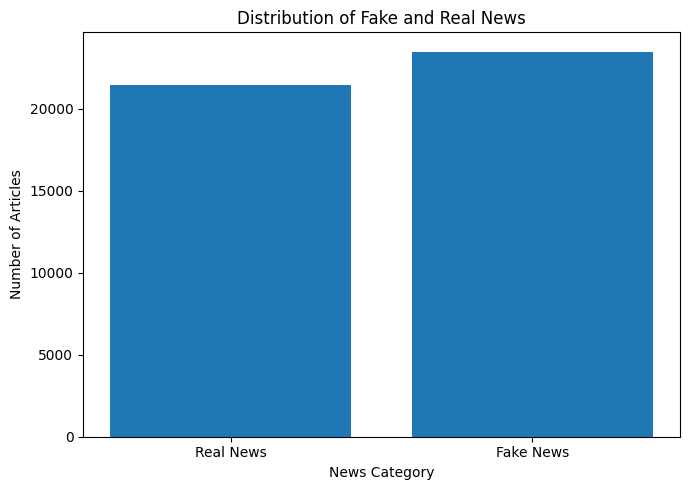

Real articles: 21417
Fake articles: 23481


In [ ]:
label_counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Real News", "Fake News"],
    [label_counts.get(0, 0), label_counts.get(1, 0)]
)
plt.title("Distribution of Fake and Real News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

print("Real articles:", label_counts.get(0, 0))
print("Fake articles:", label_counts.get(1, 0))

# **Analyze article length**

         count        mean         std  min    25%    50%    75%     max
label                                                                   
0      21417.0  393.812952  280.796790  0.0  151.0  367.0  535.0  5292.0
1      23481.0  436.335889  421.417381  0.0  248.0  375.0  521.0  8375.0


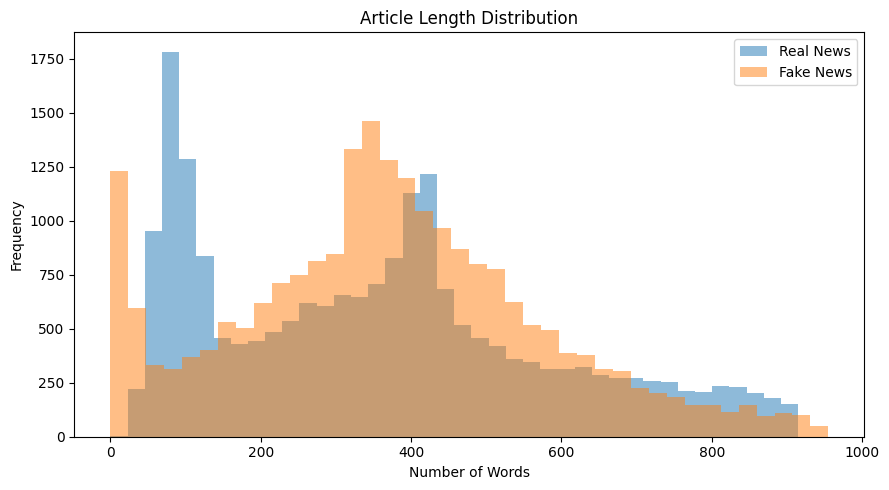

In [ ]:
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)

df["word_count"] = df["text"].apply(
    lambda text: len(re.findall(r"\b\w+\b", text))
)

print(df.groupby("label")["word_count"].describe())

plt.figure(figsize=(9, 5))

for label, name in [(0, "Real News"), (1, "Fake News")]:
    values = df.loc[df["label"] == label, "word_count"]
    values = values[values <= values.quantile(0.95)]

    plt.hist(values, bins=40, alpha=0.5, label=name)

plt.title("Article Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

# **Extract linguistic features**

# Install the sentiment-analysis dependency

In [ ]:
%pip -q install textblob

# **Define the linguistic feature extractor**

In [ ]:
from textblob import TextBlob

def extract_linguistic_features(text):
    text = str(text)

    words = re.findall(r"\b\w+\b", text.lower())
    original_words = re.findall(r"\b\w+\b", text)

    word_count = len(words)
    char_count = len(text)

    sentence_count = len(
        [s for s in re.split(r"[.!?]+", text) if s.strip()]
    )

    uppercase_count = sum(
        1 for char in text if char.isupper()
    )

    punctuation_count = sum(
        1 for char in text if char in string.punctuation
    )

    unique_words = len(set(words))

    first_person_words = {
        "i", "me", "my", "mine", "we", "us", "our", "ours"
    }

    first_person_count = sum(
        1 for word in words if word in first_person_words
    )

    sentiment = TextBlob(text).sentiment.polarity

    return {
        "word_count": word_count,
        "sentence_count": sentence_count,
        "avg_word_length": (
            np.mean([len(word) for word in words])
            if words else 0
        ),
        "avg_sentence_length": (
            word_count / sentence_count
            if sentence_count else 0
        ),
        "uppercase_ratio": (
            uppercase_count / char_count
            if char_count else 0
        ),
        "exclamation_count": text.count("!"),
        "question_count": text.count("?"),
        "punctuation_ratio": (
            punctuation_count / char_count
            if char_count else 0
        ),
        "lexical_diversity": (
            unique_words / word_count
            if word_count else 0
        ),
        "first_person_ratio": (
            first_person_count / word_count
            if word_count else 0
        ),
        "sentiment_polarity": sentiment
    }

# **Extract features for all articles**

In [ ]:
df["combined_text"] = (
    df["title"].str.strip() + " " + df["text"].str.strip()
).str.strip()

feature_records = df["combined_text"].apply(
    extract_linguistic_features
)

linguistic_df = pd.DataFrame(
    feature_records.tolist(),
    index=df.index
)

print("Linguistic feature matrix shape:", linguistic_df.shape)

display(linguistic_df.head())

Linguistic feature matrix shape: (44898, 11)


,word_count,sentence_count,avg_word_length,avg_sentence_length,uppercase_ratio,exclamation_count,question_count,punctuation_ratio,lexical_diversity,first_person_ratio,sentiment_polarity
0,517,35,4.491296,14.771429,0.050135,6,9,0.041050,0.477756,0.019342,0.072534
1,324,20,4.975309,16.200000,0.048805,0,0,0.019827,0.601852,0.006173,-0.020811
2,624,48,4.687500,13.000000,0.087605,2,4,0.040141,0.496795,0.027244,-0.012345
3,489,34,4.597137,14.382353,0.049790,0,1,0.042076,0.523517,0.008180,-0.038021
4,433,20,4.461894,21.650000,0.030629,0,0,0.016556,0.515012,0.020785,-0.011722


# **Compare linguistic features across the two classes**

In [ ]:
feature_comparison = linguistic_df.join(
    df["label"].rename("label")
).groupby("label").mean().T

feature_comparison.columns = [
    "Real News Mean",
    "Fake News Mean"
]

feature_comparison["Difference"] = (
    feature_comparison["Fake News Mean"]
    - feature_comparison["Real News Mean"]
)

display(feature_comparison.round(4))

,Real News Mean,Fake News Mean,Difference
word_count,404.3267,451.8760,47.5494
sentence_count,21.3910,23.8088,2.4179
avg_word_length,4.9374,4.7097,-0.2278
avg_sentence_length,20.6327,19.4902,-1.1425
uppercase_ratio,0.0421,0.0724,0.0303
exclamation_count,0.0628,0.8765,0.8137
question_count,0.1073,1.2798,1.1724
punctuation_ratio,0.0221,0.0241,0.0019
lexical_diversity,0.5639,0.5700,0.0061
first_person_ratio,0.0062,0.0128,0.0066


# **Visualize selected linguistic features**

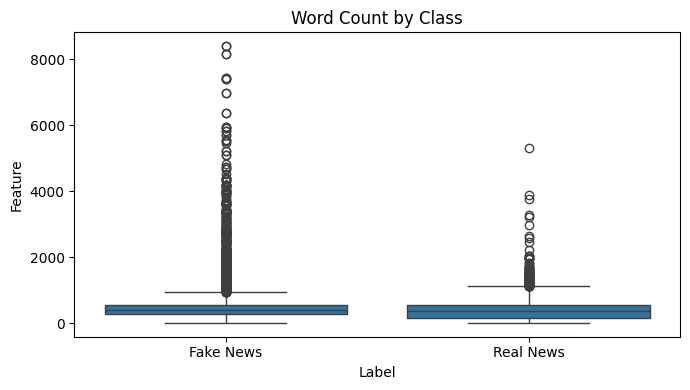

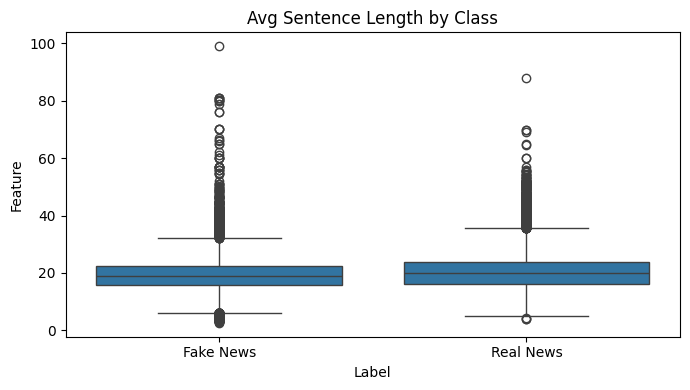

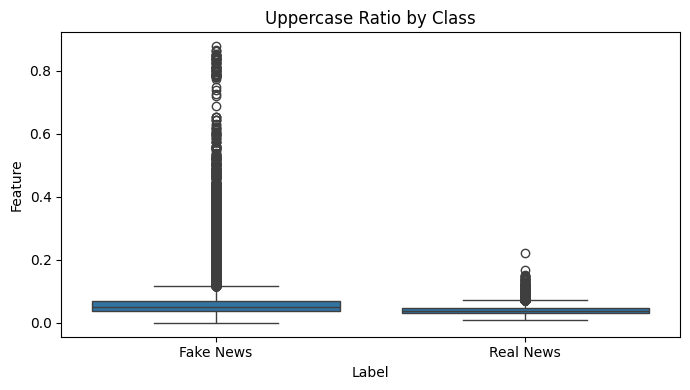

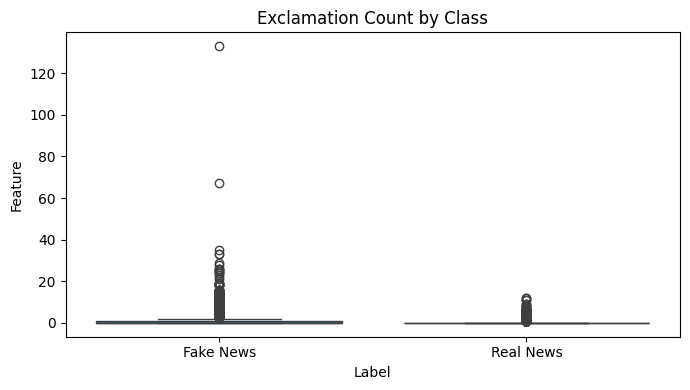

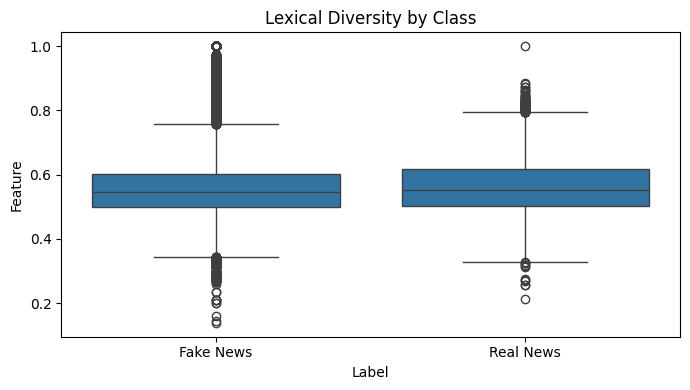

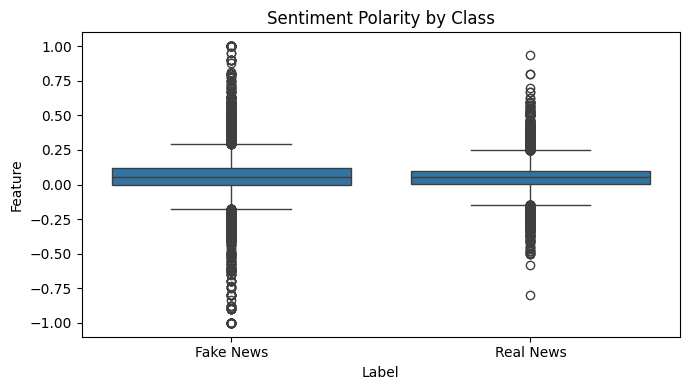

In [ ]:
selected_features = [
    "word_count",
    "avg_sentence_length",
    "uppercase_ratio",
    "exclamation_count",
    "lexical_diversity",
    "sentiment_polarity"
]

for feature in selected_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=pd.DataFrame({
            "Feature": linguistic_df[feature],
            "Label": df["label"].map({
                0: "Real News",
                1: "Fake News"
            })
        }),
        x="Label",
        y="Feature"
    )

    plt.title(f"{feature.replace('_', ' ').title()} by Class")
    plt.tight_layout()
    plt.show()

# **Remove duplicates and split the dataset**

In [ ]:
data = df.copy()

data["combined_text"] = (
    data["title"].fillna("").astype(str).str.strip()
    + " "
    + data["text"].fillna("").astype(str).str.strip()
).str.strip()

data = data[
    data["combined_text"].str.len() > 0
].copy()

data = data.drop_duplicates(
    subset=["combined_text"],
    keep="first"
).reset_index(drop=True)

linguistic_df = linguistic_df.loc[data.index].copy()

X_text = data["combined_text"]
y = data["label"]

X_train_text, X_test_text, y_train, y_test, train_idx, test_idx = (
    train_test_split(
        X_text,
        y,
        data.index,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

X_train_ling = linguistic_df.loc[train_idx]
X_test_ling = linguistic_df.loc[test_idx]

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 31282
Testing samples: 7821

Training class distribution:
label
0    16957
1    14325
Name: count, dtype: int64

Testing class distribution:
label
0    4239
1    3582
Name: count, dtype: int64


# **Rebuild aligned features after deduplication**

In [ ]:
data = df.copy()

data["combined_text"] = (
    data["title"].fillna("").astype(str).str.strip()
    + " "
    + data["text"].fillna("").astype(str).str.strip()
).str.strip()

data = data[data["combined_text"].str.len() > 0].copy()

data = data.drop_duplicates(
    subset=["combined_text"],
    keep="first"
).reset_index(drop=True)

linguistic_df = pd.DataFrame(
    data["combined_text"].apply(
        extract_linguistic_features
    ).tolist()
)

X_text = data["combined_text"]
y = data["label"]

indices = np.arange(len(data))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_text = X_text.iloc[train_idx]
X_test_text = X_text.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

X_train_ling = linguistic_df.iloc[train_idx]
X_test_ling = linguistic_df.iloc[test_idx]

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

Training samples: 31282
Testing samples: 7821


# **Convert text into TF-IDF features**

In [ ]:
tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words="english",
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (31282, 30000)
Testing TF-IDF shape: (7821, 30000)


# **Standardize the linguistic features**

In [ ]:
scaler = StandardScaler()

X_train_ling_scaled = scaler.fit_transform(X_train_ling)
X_test_ling_scaled = scaler.transform(X_test_ling)

X_train_ling_sparse = csr_matrix(X_train_ling_scaled)
X_test_ling_sparse = csr_matrix(X_test_ling_scaled)

X_train_combined = hstack([
    X_train_tfidf,
    X_train_ling_sparse
]).tocsr()

X_test_combined = hstack([
    X_test_tfidf,
    X_test_ling_sparse
]).tocsr()

print("TF-IDF feature shape:", X_train_tfidf.shape)
print("Linguistic feature shape:", X_train_ling_sparse.shape)
print("Combined feature shape:", X_train_combined.shape)

TF-IDF feature shape: (31282, 30000)
Linguistic feature shape: (31282, 11)
Combined feature shape: (31282, 30011)


# **Train and compare the machine learning models**

In [ ]:
models = {
    "TF-IDF + Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        X_train_tfidf,
        X_test_tfidf
    ),

    "TF-IDF + Linear SVM": (
        LinearSVC(random_state=42),
        X_train_tfidf,
        X_test_tfidf
    ),

    "Linguistic Features + Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        X_train_ling_sparse,
        X_test_ling_sparse
    ),

    "Combined Features + Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        X_train_combined,
        X_test_combined
    )
}

results = []
trained_models = {}
predictions = {}

for name, (model, X_train, X_test) in models.items():
    print(f"\nTraining: {name}")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Macro F1", ascending=False
    ).round(4)
)


Training: TF-IDF + Logistic Regression

Training: TF-IDF + Linear SVM

Training: Linguistic Features + Logistic Regression

Training: Combined Features + Logistic Regression


,Model,Accuracy,Precision,Recall,F1 Score,Macro F1
1,TF-IDF + Linear SVM,0.9958,0.9964,0.9944,0.9954,0.9957
0,TF-IDF + Logistic Regression,0.9895,0.9938,0.9832,0.9885,0.9894
3,Combined Features + Logistic Regression,0.9889,0.9888,0.9869,0.9878,0.9888
2,Linguistic Features + Logistic Regression,0.8351,0.8511,0.7755,0.8116,0.8325


# **Plot the model comparison**

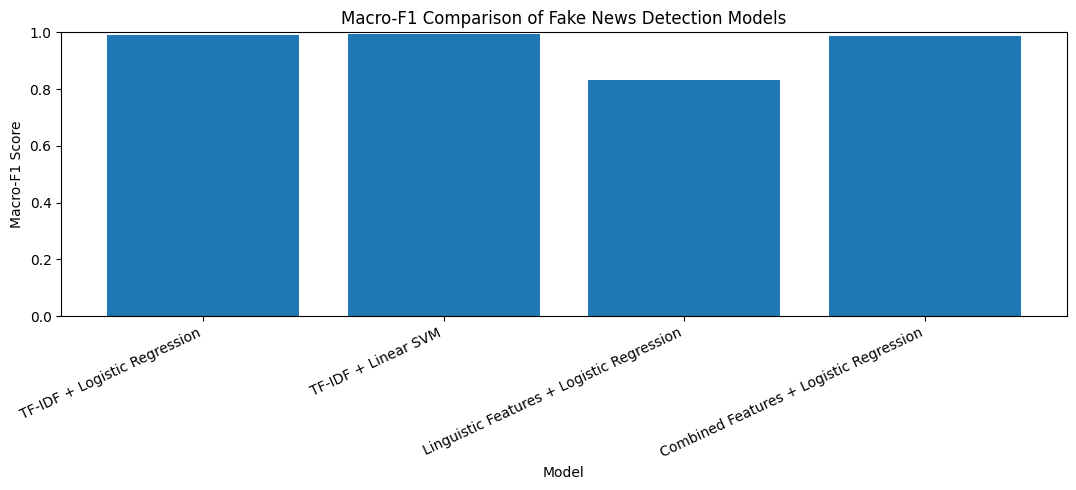

In [ ]:
plt.figure(figsize=(11, 5))

plt.bar(
    results_df["Model"],
    results_df["Macro F1"]
)

plt.title("Macro-F1 Comparison of Fake News Detection Models")
plt.xlabel("Model")
plt.ylabel("Macro-F1 Score")
plt.ylim(0, 1)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# **Analyze the confusion matrix**

Model: Combined Features + Logistic Regression

Classification Report:
              precision    recall  f1-score   support

   Real News       0.99      0.99      0.99      4239
   Fake News       0.99      0.99      0.99      3582

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821



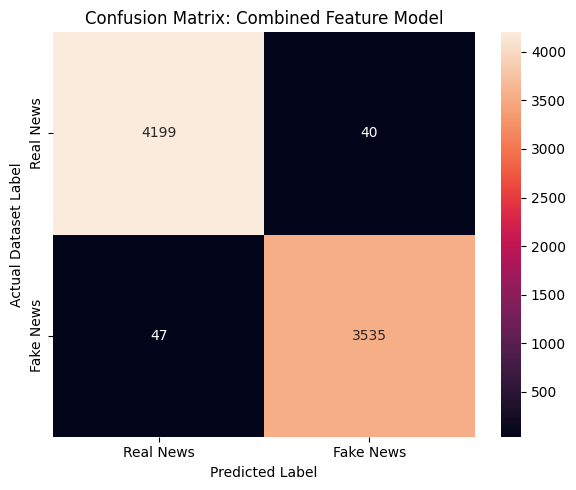

In [ ]:
best_model_name = "Combined Features + Logistic Regression"

y_pred = predictions[best_model_name]

print("Model:", best_model_name)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Real News", "Fake News"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Real News", "Fake News"],
    yticklabels=["Real News", "Fake News"]
)

plt.title("Confusion Matrix: Combined Feature Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Dataset Label")
plt.tight_layout()
plt.show()

# **Identify the most influential linguistic features**

,Feature,Coefficient,Absolute Coefficient
4,uppercase_ratio,3.0668,3.0668
1,sentence_count,-0.8706,0.8706
5,exclamation_count,0.8689,0.8689
6,question_count,0.6966,0.6966
0,word_count,0.6075,0.6075
8,lexical_diversity,-0.4551,0.4551
2,avg_word_length,-0.4410,0.4410
7,punctuation_ratio,-0.4067,0.4067
9,first_person_ratio,0.1404,0.1404
3,avg_sentence_length,-0.0617,0.0617


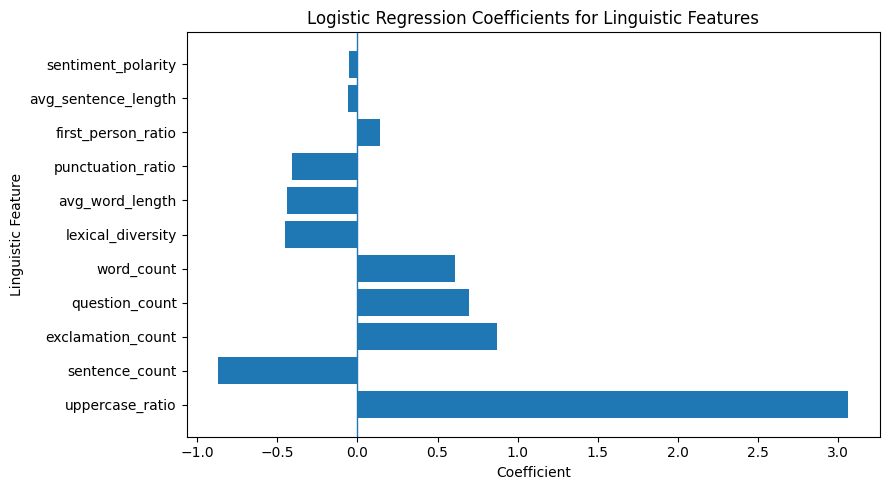

In [ ]:
combined_model = trained_models[
    "Combined Features + Logistic Regression"
]

linguistic_feature_names = linguistic_df.columns.tolist()

linguistic_coefficients = combined_model.coef_[0][
    X_train_tfidf.shape[1]:
]

importance_df = pd.DataFrame({
    "Feature": linguistic_feature_names,
    "Coefficient": linguistic_coefficients
})

importance_df["Absolute Coefficient"] = (
    importance_df["Coefficient"].abs()
)

importance_df = importance_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Coefficient"]
)

plt.axvline(0, linewidth=1)
plt.title("Logistic Regression Coefficients for Linguistic Features")
plt.xlabel("Coefficient")
plt.ylabel("Linguistic Feature")
plt.tight_layout()
plt.show()

In [ ]:
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

feature_comparison.to_csv(
    "linguistic_feature_comparison.csv"
)

importance_df.to_csv(
    "linguistic_feature_importance.csv",
    index=False
)

print("Files saved successfully:")
print("1. model_comparison_results.csv")
print("2. linguistic_feature_comparison.csv")
print("3. linguistic_feature_importance.csv")

Files saved successfully:
1. model_comparison_results.csv
2. linguistic_feature_comparison.csv
3. linguistic_feature_importance.csv


In [ ]:
from google.colab import files

files.download("model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>